# Monthly Anomalies and Arctic Climate Stripes

**Yiwen Li (YL) · 20-minute online seminar · CDO/NCO processing + NCL graphics**

This Binder demonstration reproduces [EG's shared Python notebook](https://github.com/egalytska/Fresh_eyes/blob/393cfcf876fa47c6c231c3be70dbd9f8552fe3a3/stripes_EG.ipynb), based on Abhnil's workshop.

**Same task across languages:** 1981–2010 monthly climatology → 1979–2014 monthly anomalies → Robinson map → 65–90°N monthly line → 36 annual Arctic stripes.

> Use CDO/NCO to prepare the data. Use Python to understand the data. Use NCL to render the three figures.

In [1]:
from pathlib import Path
import os
import shutil
import subprocess
import json

if Path.cwd().name == 'notebooks':
    os.chdir('..')

import numpy as np
import xarray as xr
from IPython.display import Image, display

DATA = Path(os.environ.get('WORKSHOP_INPUT', 'data/demo/tas_demo.nc'))
ROOT = Path('outputs/yl_monthly')
assert DATA.is_file(), f'Missing input: {DATA}. Run make demo-data or provide WORKSHOP_INPUT.'
for tool in ('cdo', 'ncks', 'ncwa', 'ncl'):
    assert shutil.which(tool), f'Missing tool: {tool}'
with xr.open_dataset(DATA) as ds:
    print('Input:', DATA)
    print('Dataset:', ds.attrs.get('title', ds.attrs.get('source_id', 'Inspect provenance')))
    print('Summary:', ds.attrs.get('summary', 'Use the original CMIP data citation.'))
    synthetic = ds.attrs.get('source_id') == 'WORKSHOP-DEMO'
print('SYNTHETIC teaching data; not CMIP model results.' if synthetic else 'External data: check model, member, calendar and grid against EG.')

Input: data/demo/tas_demo.nc
Dataset: Deterministic CMIP-style teaching dataset
Summary: Synthetic data for CDO/NCO/Python software comparison; not for scientific conclusions.
SYNTHETIC teaching data; not CMIP model results.


## 0:00–2:00 | The same three figures, in another toolchain

The default Binder input is a deterministic **synthetic teaching dataset**, with the same monthly variable structure and time span as the original ACCESS-CM2 file. It demonstrates the calculation, not actual model warming. Full ACCESS-CM2 data can be supplied via `WORKSHOP_INPUT` for an identical-data comparison; a spatially strided sample will produce different regional values.

**Chat prompt:** What does a monthly anomaly compare January with?

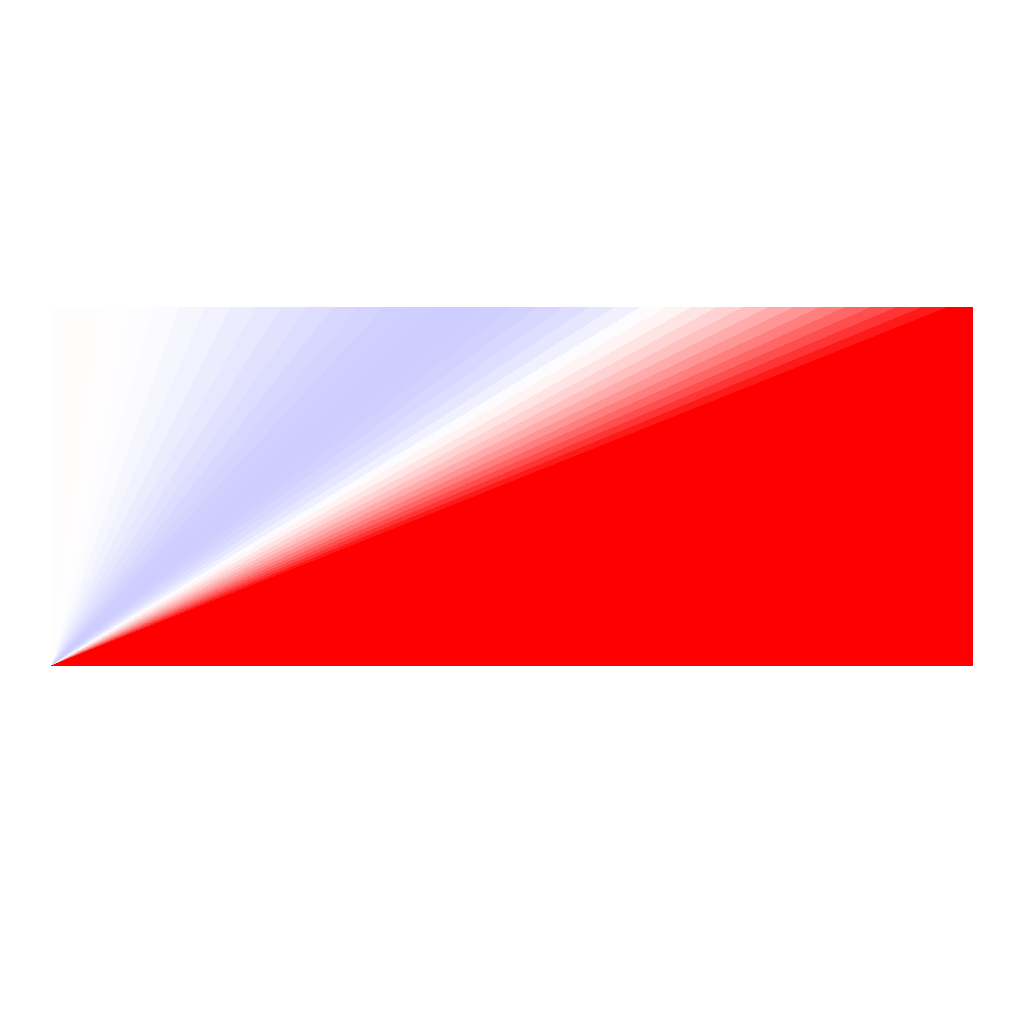

Preview: synthetic Arctic annual anomalies, 1979–2014; baseline 1981–2010.


In [2]:
preview = Path('outputs/demo/monthly/03_arctic_annual_stripes.png')
if preview.exists() and synthetic:
    display(Image(filename=str(preview), width=900))
    print('Preview: synthetic Arctic annual anomalies, 1979–2014; baseline 1981–2010.')
else:
    print('The three figures will be generated below.')

## 2:00–4:00 | Inspect variable, calendar, period and grid

EG uses ACCESS-CM2 historical `r1i1p1f1`, Amon `tas`, grid `gn`, version `v20191108`, 1850–2014. The tutorial analyses 1979–2014 and builds its baseline from 1981–2010. Confirm all baseline months are available before selecting the analysis period.

In [3]:
summary = subprocess.run(['cdo', '-s', 'sinfo', str(DATA)], check=True, capture_output=True, text=True)
print(summary.stdout)
with xr.open_dataset(DATA) as ds:
    display(ds.tas)
    assert int(ds.time.dt.year.min()) <= 1981 and int(ds.time.dt.year.max()) >= 2014

   File format : NetCDF4 zip
    -1 : Institut Source   T Steptype Levels Num    Points Num Dtype : Parameter ID
     1 : unknown  unknown  v instant       1   1      2592   1  F32z : -1            
   Grid coordinates :
     1 : lonlat                   : points=2592 (72x36)
                              lon : 2.5 to 357.5 by 5 degrees_east  circular
                              lat : -87.5 to 87.5 by 5 degrees_north
   Vertical coordinates :
     1 : surface                  : levels=1
   Time coordinate :
                             time : 1980 steps
     RefTime =  1850-01-15 00:00:00  Units = days  Calendar = proleptic_gregorian
  YYYY-MM-DD hh:mm:ss  YYYY-MM-DD hh:mm:ss  YYYY-MM-DD hh:mm:ss  YYYY-MM-DD hh:mm:ss
  1850-01-15 00:00:00  1850-02-15 00:00:00  1850-03-15 00:00:00  1850-04-15 00:00:00
  1850-05-15 00:00:00  1850-06-15 00:00:00  1850-07-15 00:00:00  1850-08-15 00:00:00
  1850-09-15 00:00:00  1850-10-15 00:00:00  1850-11-15 00:00:00  1850-12-15 00:00:00
  1851-01-15 00:

<xarray.DataArray 'tas' (time: 1980, lat: 36, lon: 72)> Size: 21MB
[5132160 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 16kB 1850-01-15 1850-02-15 ... 2014-12-15
  * lat      (lat) float32 144B -87.5 -82.5 -77.5 -72.5 ... 72.5 77.5 82.5 87.5
  * lon      (lon) float32 288B 2.5 7.5 12.5 17.5 ... 342.5 347.5 352.5 357.5
Attributes:
    standard_name:  air_temperature
    long_name:      Near-Surface Air Temperature
    units:          K
    cell_methods:   area: time: mean

## 4:00–6:30 | Python reference: follow EG's definitions

A monthly anomaly subtracts the **matching calendar month's** 1981–2010 climatology at each grid cell. The Arctic series is the simple arithmetic mean of grid points at 65–90°N. Area weighting would change EG's calculation.

The annual mean gives each monthly sample equal weight, as in the reference notebook.

In [4]:
with xr.open_dataset(DATA) as ds:
    tas = (ds.tas - 273.15).load()
tas_ref = tas.sel(time=slice('1981-01-01', '2010-12-31'))
tas_clim = tas_ref.groupby('time.month').mean('time')
tas_anom = tas.groupby('time.month') - tas_clim
tas_anom = tas_anom.sel(time=slice('1979-01-01', '2014-12-31'))
mean_map = tas_anom.mean('time')
arctic = tas_anom.where((tas_anom.lat >= 65) & (tas_anom.lat <= 90), drop=True)
arctic_monthly = arctic.mean(('lat', 'lon'))
arctic_annual = arctic_monthly.groupby('time.year').mean('time')
print(f'{tas_clim.sizes["month"]} climatology months; {tas_anom.sizes["time"]} anomaly months; {arctic_annual.size} annual stripes')

12 climatology months; 432 anomaly months; 36 annual stripes


## 6:30–11:00 | CDO/NCO: the same operations

| Python task | CDO/NCO operation |
|---|---|
| `ds.tas` | `ncks -v tas` |
| Kelvin → Celsius | `cdo subc,273.15` |
| 1981–2010 monthly climatology | `cdo ymonmean -selyear,1981/2010` |
| Subtract matching climatology month | `cdo ymonsub` |
| Retain 1979–2014 | `cdo seldate,1979-01-01,2014-12-31` |
| Mean anomaly map | `cdo timmean` |
| Select 65–90°N | `ncks -d lat,65.0,90.0` |
| Unweighted Arctic grid-point mean | `ncwa -a lat,lon` |
| Annual mean | `cdo yearmean` |

Read CDO chains from right to left. Show the prepared script, then run it; do not type the full workflow during the talk.

In [5]:
print(Path('scripts/run_cdo_nco_monthly_anomaly.sh').read_text())

#!/usr/bin/env bash
set -euo pipefail

input=${1:-data/demo/tas_demo.nc}
output_dir=${2:-outputs/demo/monthly/cdo_nco}

mkdir -p "${output_dir}"

# NCO keeps only the shared seminar variable before CDO starts processing.
ncks -O -v tas "${input}" "${output_dir}/tas_selected.nc"

# Exact reproduction of the shared Python example:
# Kelvin -> Celsius; 1981-2010 monthly climatology; monthly anomalies;
# then retain 1979-2014.
cdo -L -f nc4c -z zip_4 subc,273.15 \
  "${output_dir}/tas_selected.nc" \
  "${output_dir}/tas_degC.nc"

cdo -L -f nc4c -z zip_4 ymonmean \
  -selyear,1981/2010 \
  "${output_dir}/tas_degC.nc" \
  "${output_dir}/tas_monthly_climatology_1981_2010.nc"

cdo -L -f nc4c -z zip_4 ymonsub \
  "${output_dir}/tas_degC.nc" \
  "${output_dir}/tas_monthly_climatology_1981_2010.nc" \
  "${output_dir}/tas_monthly_anomaly_full.nc"

cdo -L -f nc4c -z zip_4 seldate,1979-01-01,2014-12-31 \
  "${output_dir}/tas_monthly_anomaly_full.nc" \
  "${output_dir}/tas_monthly_anomaly_1979_2014.n

In [6]:
subprocess.run(['bash', 'scripts/run_cdo_nco_monthly_anomaly.sh', str(DATA), str(ROOT / 'cdo_nco')], check=True)

CDO/NCO monthly-anomaly workflow complete: outputs/yl_monthly/cdo_nco


CompletedProcess(args=['bash', 'scripts/run_cdo_nco_monthly_anomaly.sh', 'data/demo/tas_demo.nc', 'outputs/yl_monthly/cdo_nco'], returncode=0)

## 11:00–13:00 | Verify all four scientific outputs

Compare every monthly grid-cell anomaly, the mean map, the Arctic monthly series, and the Arctic annual series. Check 432 months, 36 years, and a near-zero baseline for each calendar month. A visually similar plot alone is insufficient.

In [7]:
subprocess.run(['python', 'scripts/run_python_monthly_anomaly.py', str(DATA), str(ROOT / 'python')], check=True)
subprocess.run(['python', 'scripts/validate_monthly_anomaly.py', '--cdo-nco', str(ROOT / 'cdo_nco'), '--python', str(ROOT / 'python'), '--report', str(ROOT / 'validation.json')], check=True)
report = json.loads((ROOT / 'validation.json').read_text())
assert all(item['passed'] for item in report.values())
print('PASS: independent CDO/NCO and xarray results agree.')

/workspaces/Fresh-Eyes-CDO-NCO-Workshop/workshop.py:13: FutureWarning: Usage of 'use_cftime' as a kwarg is deprecated. Please pass a 'CFDatetimeCoder' instance initialized with 'use_cftime' to the 'decode_times' kwarg instead.
Example usage:
    time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)
    ds = xr.open_dataset(decode_times=time_coder)

  tas = xr.open_dataset(path, use_cftime=True)["tas"]


Python monthly-anomaly workflow complete: outputs/yl_monthly/python


{
  "monthly_anomaly_1979_2014": {
    "max_absolute_difference": 7.62939453125e-06,
    "tolerance": 0.0003,
    "passed": true
  },
  "mean_monthly_anomaly_map_1979_2014": {
    "max_absolute_difference": 1.9073486328125e-06,
    "tolerance": 0.0003,
    "passed": true
  },
  "arctic_monthly_unweighted_1979_2014": {
    "max_absolute_difference": 4.172325134277344e-07,
    "tolerance": 0.0003,
    "passed": true
  },
  "arctic_annual_unweighted_1979_2014": {
    "max_absolute_difference": 5.960464477539063e-08,
    "tolerance": 0.0003,
    "passed": true
  }
}
All shared-example results agree within tolerance.
PASS: independent CDO/NCO and xarray results agree.


## 13:00–17:00 | NCL renders the three reference figures

NCL reads the processed NetCDF files. The Robinson map uses `coolwarm` and the shared −0.2 to +0.4 °C range. The line shows all 432 monthly Arctic anomalies. The stripes show one equal-width rectangle per year using blue–white–red and ±max(|annual anomaly|).

**Display convention:** NCL fonts and coastlines may differ from matplotlib/cartopy. The scientific arrays and colour normalization are the comparison target.

In [8]:
subprocess.run(['ncl', f'input_dir="{ROOT / "cdo_nco"}"', f'output_dir="{ROOT}"', 'scripts/make_eg_figures.ncl'], check=True)
subprocess.run(['python', 'scripts/check_ncl_outputs.py', str(ROOT)], check=True)

 Copyright (C) 1995-2019 - All Rights Reserved
 University Corporation for Atmospheric Research
 NCAR Command Language Version 6.6.2
 The use of this software is governed by a License Agreement.
 See http://www.ncl.ucar.edu/ for more details.
(0)	NCL wrote all three EG figures to outputs/yl_monthly
(0)	Arctic annual stripes: 36 years; symmetric limit +/-0.273591 degC
PASS: 01_mean_anomaly_map.png (1024 x 1024)
PASS: 02_arctic_monthly_anomaly.png (1024 x 1024)
PASS: 03_arctic_annual_stripes.png (1024 x 1024)


CompletedProcess(args=['python', 'scripts/check_ncl_outputs.py', 'outputs/yl_monthly'], returncode=0)

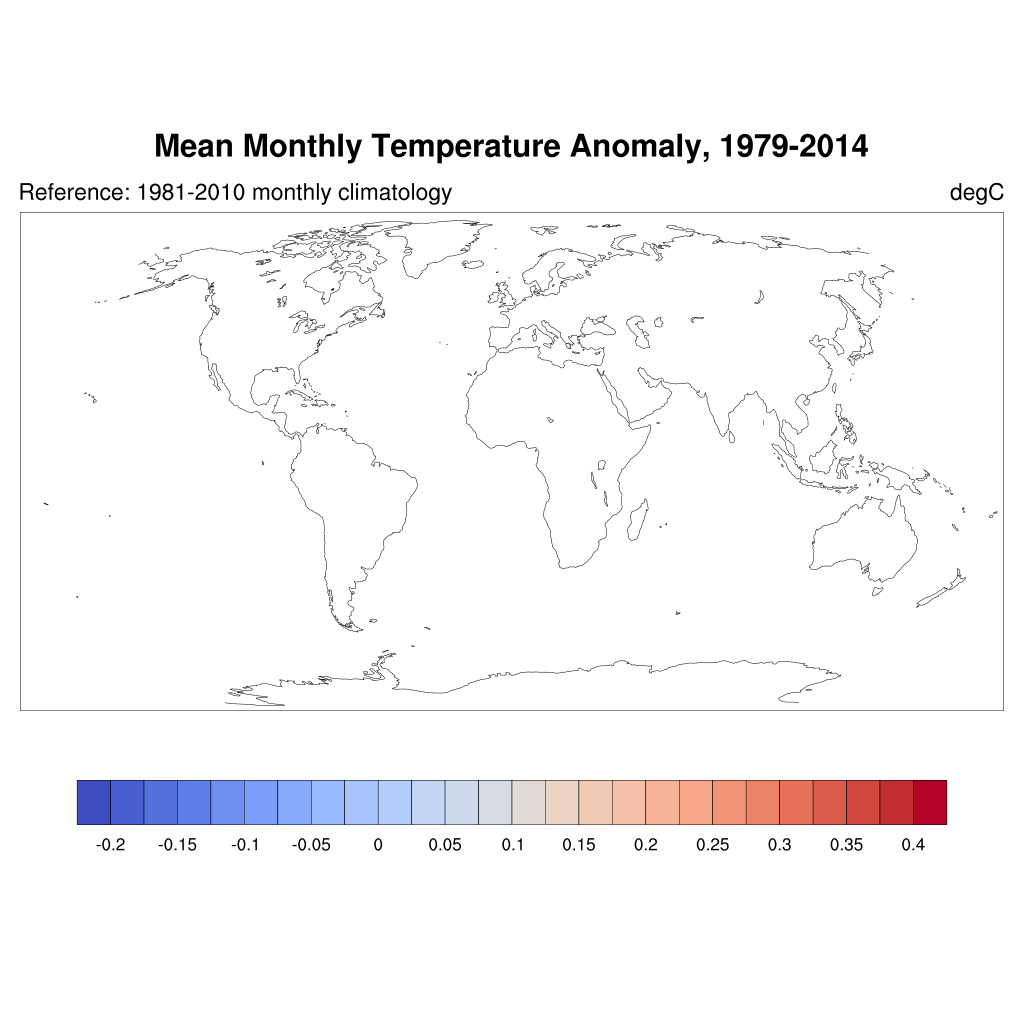

Mean of 1979–2014 monthly anomalies relative to 1981–2010 monthly climatology.


In [9]:
display(Image(filename=str(ROOT / '01_mean_anomaly_map.png'), width=900))
print('Mean of 1979–2014 monthly anomalies relative to 1981–2010 monthly climatology.')

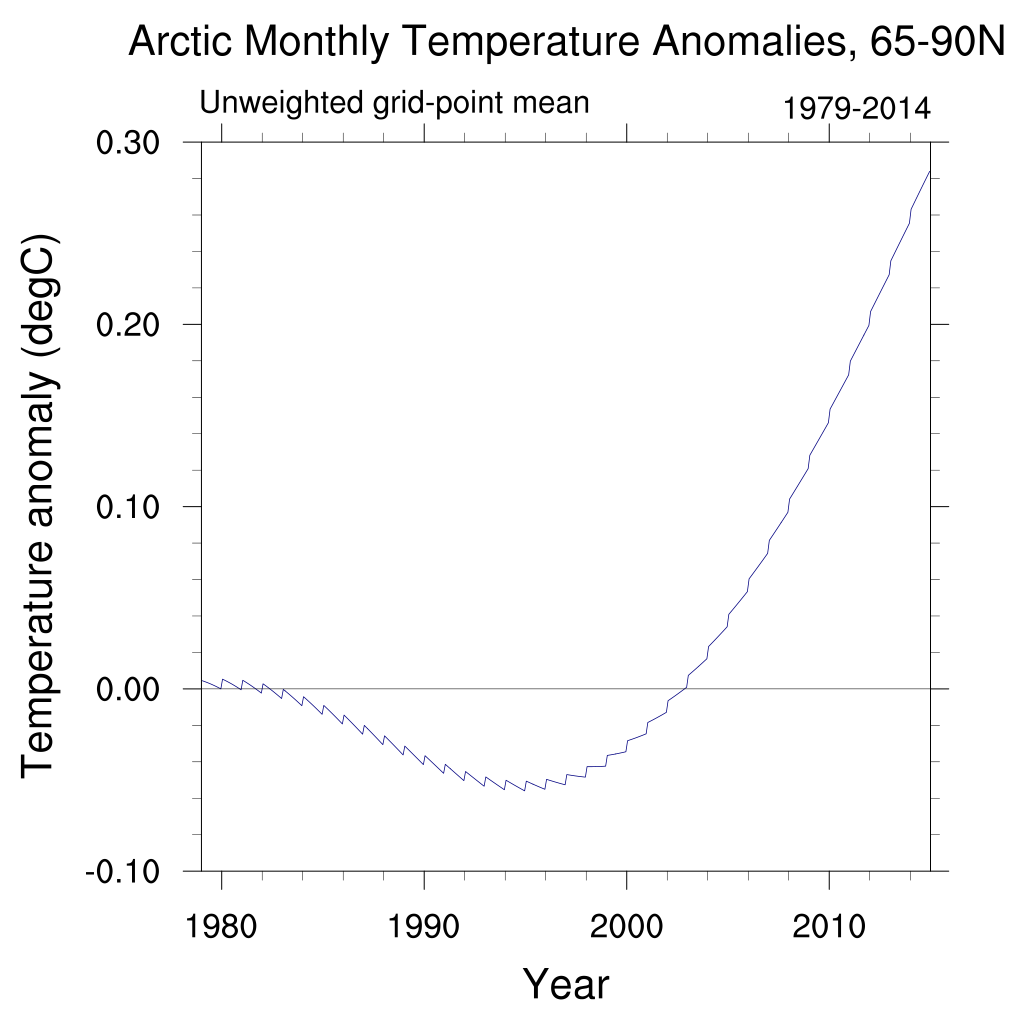

65–90°N arithmetic grid-point mean, 432 monthly values; no area weighting.


In [10]:
display(Image(filename=str(ROOT / '02_arctic_monthly_anomaly.png'), width=900))
print('65–90°N arithmetic grid-point mean, 432 monthly values; no area weighting.')

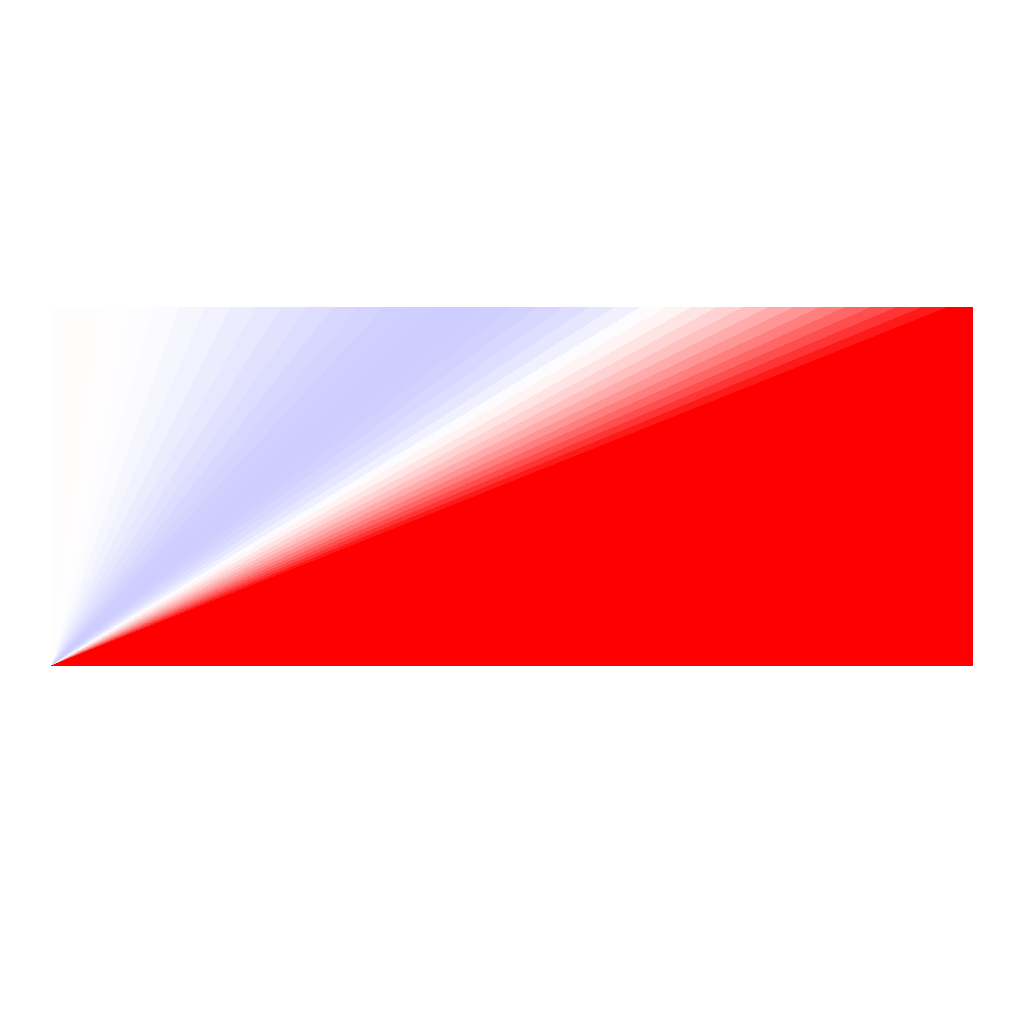

Arctic annual stripes: 1979–2014, 36 years, equal monthly weights.
Symmetric colour limit: ±0.2736 °C


In [11]:
display(Image(filename=str(ROOT / '03_arctic_annual_stripes.png'), width=900))
print('Arctic annual stripes: 1979–2014, 36 years, equal monthly weights.')
print(f'Symmetric colour limit: ±{float(abs(arctic_annual).max()):.4f} °C')

## 17:00–19:00 | Predict, then test in the hands-on session

1. What changes if the baseline is 1981–2000? Both Python and CDO must change the **same** baseline.
2. What changes if an Arctic area-weighted mean replaces the arithmetic mean? Treat that as an extension and change both implementations.
3. Why can annual averaging still show warming after removing the seasonal cycle?

Keep these as predictions during the 20-minute talk. Use `notebooks/04_monthly_anomaly_hands_on.ipynb` in the shared hands-on block. Binder sessions are temporary: download your notebook/results before leaving.

## 19:00–20:00 | Tool choice and handoff

CDO expresses monthly climatology and anomalies concisely. NCO preserves the reference's exact Arctic mean and edits metadata. Python checks and explains the results. NCL renders the three climate graphics.

**Takeaway:** Use CDO/NCO to prepare the data. Use Python to understand the data.

Source audit and exact mapping: [docs/EG_SHARED_NOTEBOOK_MAPPING.md](../docs/EG_SHARED_NOTEBOOK_MAPPING.md).